# 2. Reported results of RS-FEDRAD

This notebook gathers the results reported in the RS-FEDRAD article. The round-wise federated performance is rebuilt from the original per-client training logs in `results/logs/federated`; the remaining tables are stored in `results/tables`, and the figures are those of the article.

In [1]:
import os, sys, warnings
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"
warnings.filterwarnings("ignore")
from pathlib import Path
ROOT = Path.cwd().parent
sys.path.insert(0, str(ROOT / "src"))
import numpy as np
import pandas as pd
from IPython.display import Image, display
from rsfedrad import config

## 2.1 Federated training with FedAvg (10 clients, 10 rounds, 10 local epochs)

Each client logs, after every round, its local accuracy together with precision, recall and F1-score on its held-out split. The global figures are the mean over the ten clients.

In [2]:
from rsfedrad.aggregate_logs import aggregate

table, n = aggregate(config.LOGS_DIR / "federated")
print(f"aggregated over {n} clients")
table

aggregated over 10 clients


,Round,Accuracy,Precision,Recall,F1-score
0,1,98.56,97.87,97.49,97.66
1,2,99.17,97.58,98.76,98.16
2,3,99.51,97.86,98.66,98.27
3,4,99.39,98.52,98.34,98.52
4,5,99.71,98.75,98.86,98.87
5,6,99.70,98.82,98.98,98.94
6,7,99.63,98.99,98.86,98.92
7,8,99.83,98.90,99.08,98.99
8,9,99.82,98.93,98.79,98.86
9,10,99.90,99.22,99.12,99.13


identical to the published table: True
average over rounds: {'Accuracy': 99.52, 'Precision': 98.54, 'Recall': 98.69, 'F1-score': 98.63}


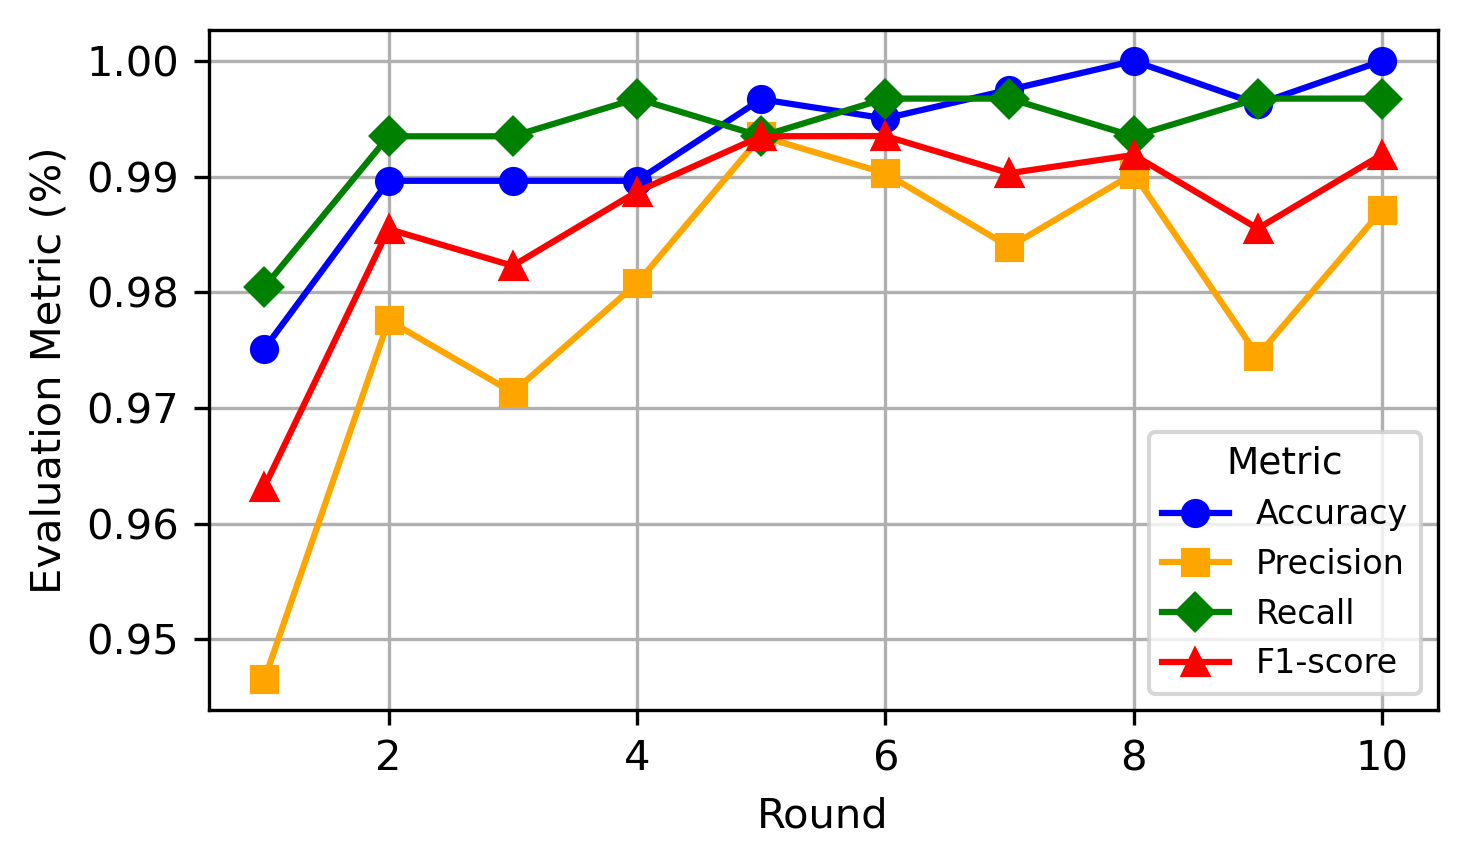

In [3]:
published = pd.read_csv(config.TABLES_DIR / "federated_rounds.csv")
print("identical to the published table:", np.allclose(table.iloc[:, 1:], published.iloc[:, 1:], atol=0.005))
print("average over rounds:", table.iloc[:, 1:].mean().round(2).to_dict())
display(Image(str(config.FIGURES_DIR / "fig3_performance_across_rounds.png"), width=560))

## 2.2 Aggregation strategies

,Strategy,Accuracy,Precision,Recall,F1-score
0,FedAvg,99.52,98.54,98.69,98.63
1,FedProx,99.37,98.48,98.65,98.56
2,FedAvgM,99.36,98.46,98.64,98.55
3,FedMedian,99.36,98.45,98.63,98.54


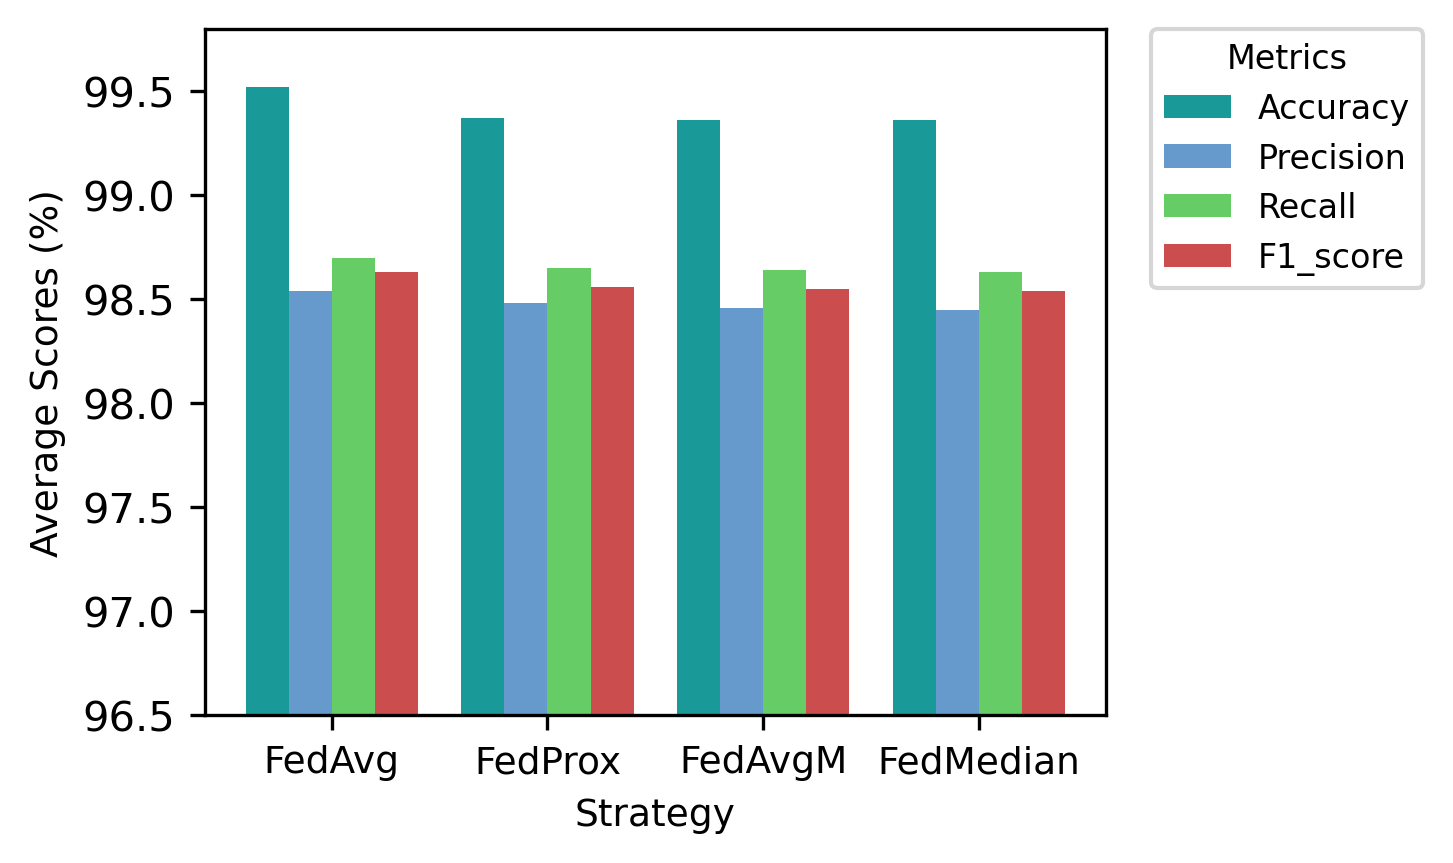

In [4]:
display(pd.read_csv(config.TABLES_DIR / "aggregation_strategies.csv"))
display(Image(str(config.FIGURES_DIR / "fig4_aggregation_strategies.png"), width=520))

## 2.3 Centralised versus federated training

In [5]:
display(pd.read_csv(config.TABLES_DIR / "centralized_vs_federated.csv"))

,Mode,Accuracy,Precision,Recall,F1-score
0,Centralized,99.12,99.10,99.31,99.20
1,Federated,99.90,99.22,99.12,99.13


## 2.4 Adversarial training (FGSM and BIM)

,Mode,Accuracy,Precision,Recall,F1-score
0,Adversarial training,99.64,99.13,99.17,99.15
1,Federated,99.90,99.22,99.12,99.13


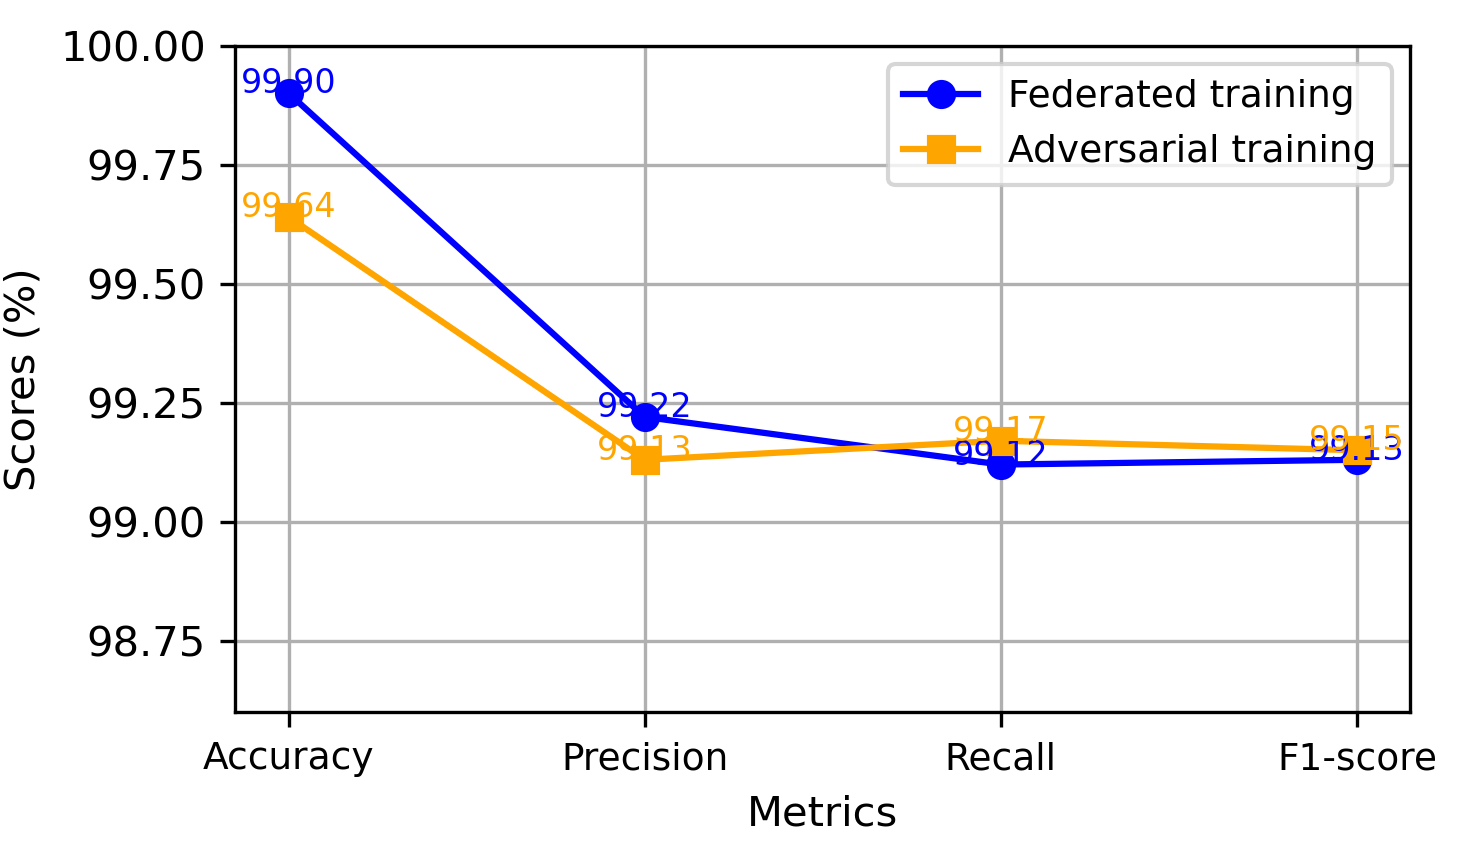

In [6]:
display(pd.read_csv(config.TABLES_DIR / "adversarial_vs_federated.csv"))
display(Image(str(config.FIGURES_DIR / "fig5_federated_vs_adversarial.png"), width=520))

## 2.5 Scalability and stability

,Clients,Accuracy,Precision,Recall,F1-score
0,10,99.52,98.54,98.70,98.63
1,15,99.57,98.60,98.75,98.68
2,20,99.50,98.48,98.67,98.60


,Metric,Mean,Standard deviation
0,Accuracy,99.507,0.035
1,Precision,98.539,0.044
2,Recall,98.695,0.050
3,F1-score,98.622,0.047
4,AUC-ROC,99.590,0.032


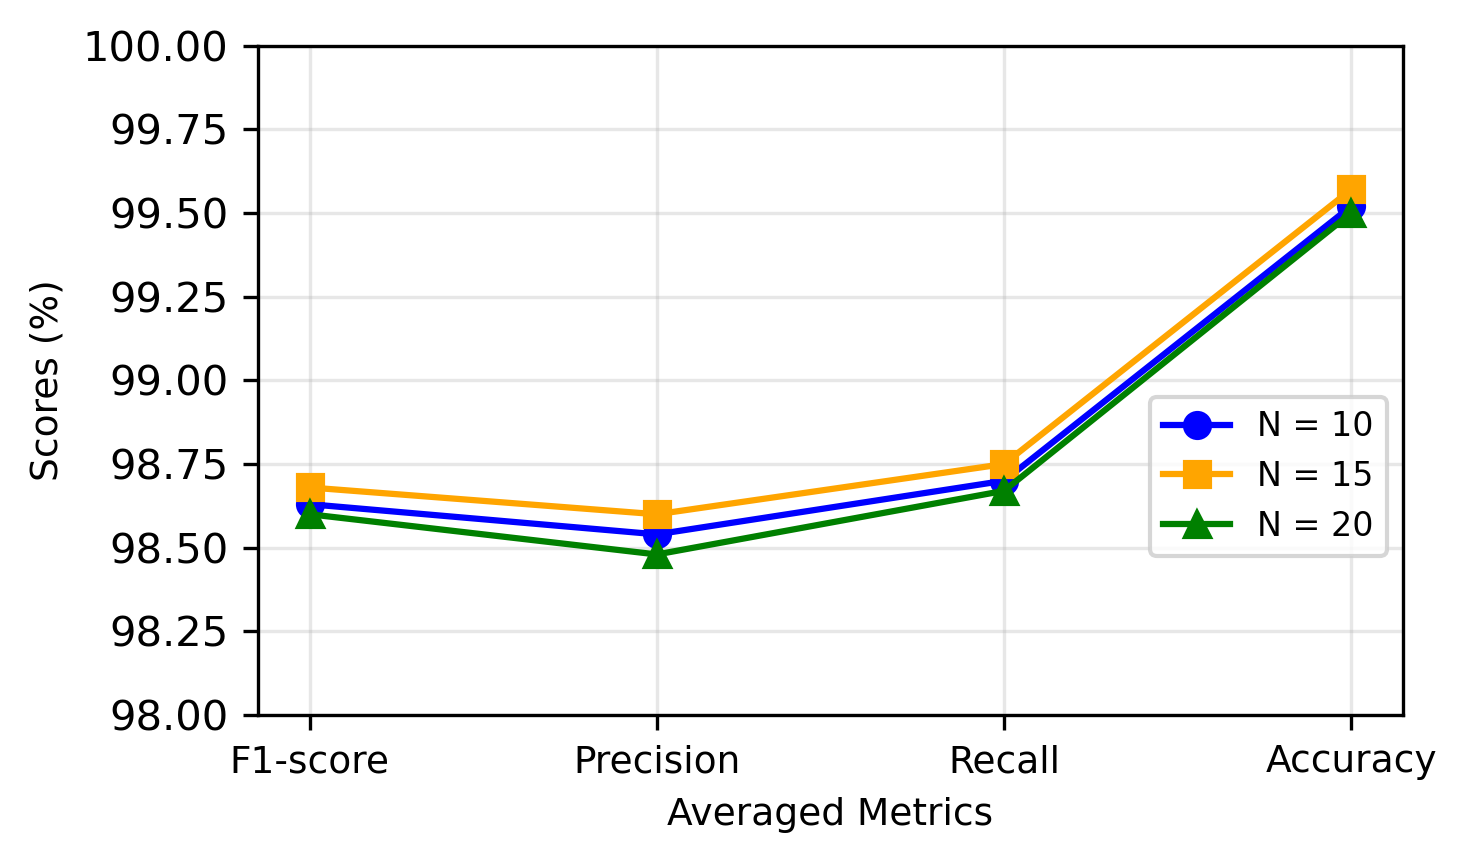

In [7]:
display(pd.read_csv(config.TABLES_DIR / "scalability.csv"))
display(pd.read_csv(config.TABLES_DIR / "stability.csv"))
display(Image(str(config.FIGURES_DIR / "fig6_scalability.png"), width=520))